# Data exploration

The audit I ran on the raw files before writing the pipeline. It checks each problem the brief warns about (missing, duplicated and impossible readings), looks at the shape of the data, and cross-checks the anomaly results. The findings drive the cleaning rules in `clean.py` and the README.

Run from the repo root:

```bash
uv run --group notebook jupyter lab notebooks/exploration.ipynb
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"

plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
COLOR = "#2a7fb8"

## 1. Load and first look

In [2]:
frames = []
for path in sorted(RAW.glob("data_group_*.csv")):
    df = pd.read_csv(path)
    df["source_file"] = path.name
    frames.append(df)
raw = pd.concat(frames, ignore_index=True)

print(raw.shape, "expected rows:", 31 * 24 * 15)
raw.head()

(11160, 6) expected rows: 11160


,timestamp,turbine_id,wind_speed,wind_direction,power_output,source_file
0,2022-03-01 00:00:00,1,11.8,169,2.7,data_group_1.csv
1,2022-03-01 00:00:00,2,11.6,24,2.2,data_group_1.csv
2,2022-03-01 00:00:00,3,13.8,335,2.3,data_group_1.csv
3,2022-03-01 00:00:00,4,12.8,238,1.9,data_group_1.csv
4,2022-03-01 00:00:00,5,11.4,103,3.5,data_group_1.csv


In [3]:
raw.groupby("source_file")["turbine_id"].unique()

source_file
data_group_1.csv         [1, 2, 3, 4, 5]
data_group_2.csv        [6, 7, 8, 9, 10]
data_group_3.csv    [11, 12, 13, 14, 15]
Name: turbine_id, dtype: object

In [4]:
raw.describe()

,turbine_id,wind_speed,wind_direction,power_output
count,11160.000000,11160.000000,11160.000000,11160.000000
mean,8.000000,12.002724,179.903943,3.001927
std,4.320687,1.735366,103.353513,0.869831
min,1.000000,9.000000,0.000000,1.500000
25%,4.000000,10.500000,91.000000,2.275000
50%,8.000000,12.000000,180.000000,3.000000
75%,12.000000,13.500000,269.000000,3.800000
max,15.000000,15.000000,359.000000,4.500000


Counts are complete and every value is physically plausible. Wind never drops below 9 m/s all month, which is unusual for real weather.

## 2. Missing and non-numeric values

Re-read as text, the way the pipeline does, so nothing is converted before we look at it.

In [5]:
text = pd.concat(
    [pd.read_csv(p, dtype=str, keep_default_na=False) for p in sorted(RAW.glob("data_group_*.csv"))]
)
blank = text.apply(lambda col: col.str.strip() == "").sum()
non_numeric = {
    col: int(pd.to_numeric(text[col], errors="coerce").isna().sum())
    for col in ["wind_speed", "wind_direction", "power_output"]
}
print("blank cells:", blank.to_dict())
print("non-numeric:", non_numeric)

blank cells: {'timestamp': 0, 'turbine_id': 0, 'wind_speed': 0, 'wind_direction': 0, 'power_output': 0}
non-numeric: {'wind_speed': 0, 'wind_direction': 0, 'power_output': 0}


## 3. Missing hours

In [6]:
raw["timestamp"] = pd.to_datetime(raw["timestamp"])

every_slot = pd.MultiIndex.from_product(
    [pd.date_range("2022-03-01 00:00", "2022-03-31 23:00", freq="h"), range(1, 16)]
)
present = pd.MultiIndex.from_frame(raw[["timestamp", "turbine_id"]])
print("expected turbine-hours:", len(every_slot))
print("missing turbine-hours: ", len(every_slot.difference(present)))
print("readings off the hour: ", int((raw["timestamp"].dt.minute != 0).sum()))

expected turbine-hours: 11160
missing turbine-hours:  0
readings off the hour:  0


## 4. Duplicates

In [7]:
print("exact duplicates:     ", raw.drop(columns="source_file").duplicated().sum())
print("same turbine and hour:", raw.duplicated(subset=["timestamp", "turbine_id"]).sum())

exact duplicates:      0
same turbine and hour: 0


## 5. Physically impossible values

In [8]:
limits = {"power_output": (0, 5), "wind_speed": (0, 50), "wind_direction": (0, 360)}
for col, (low, high) in limits.items():
    outside = ((raw[col] < low) | (raw[col] > high)).sum()
    print(f"{col}: {outside} outside {low} to {high}")

power_output: 0 outside 0 to 5
wind_speed: 0 outside 0 to 50
wind_direction: 0 outside 0 to 360


None of the problems the brief describes are present, so the cleaning rules are proven with planted bad rows in `tests/test_clean.py` instead.

## 6. Distributions

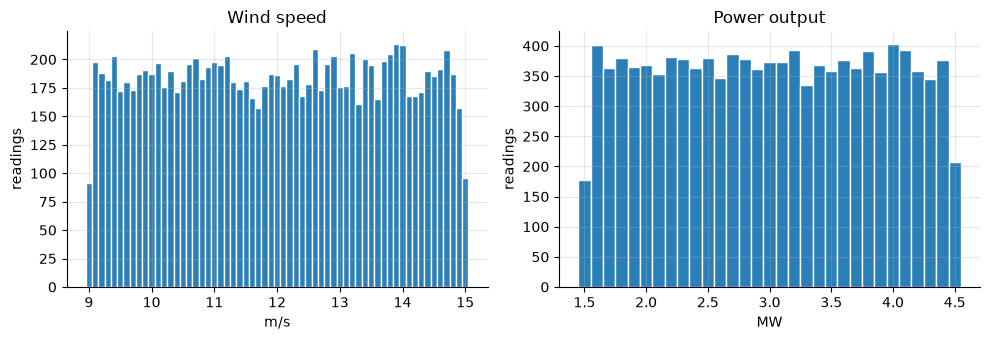

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(raw["wind_speed"], bins=np.arange(8.95, 15.1, 0.1), color=COLOR, edgecolor="white")
axes[0].set(title="Wind speed", xlabel="m/s", ylabel="readings")
axes[1].hist(raw["power_output"], bins=np.arange(1.45, 4.6, 0.1), color=COLOR, edgecolor="white")
axes[1].set(title="Power output", xlabel="MW", ylabel="readings")
plt.tight_layout()
plt.show()

Both are flat across their range (the end bins are half-height from rounding). Real wind speeds are right-skewed, so this looks like uniformly generated data.

## 7. Wind speed vs power

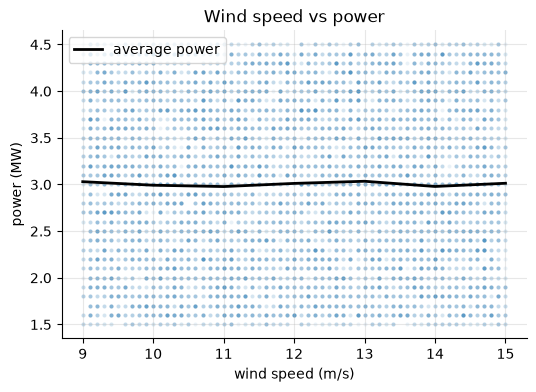

correlation: -0.0025


In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(raw["wind_speed"], raw["power_output"], s=8, alpha=0.1, color=COLOR, linewidths=0)
avg_by_wind = raw.groupby(raw["wind_speed"].round())["power_output"].mean()
ax.plot(avg_by_wind.index, avg_by_wind.values, color="black", linewidth=2, label="average power")
ax.legend(loc="upper left")
ax.set(title="Wind speed vs power", xlabel="wind speed (m/s)", ylabel="power (MW)")
plt.show()

print("correlation:", round(raw["wind_speed"].corr(raw["power_output"]), 4))

No relationship. A real turbine follows a power curve, so this needs raising with operations before the power figures are trusted.

## 8. Daily averages and the 2 SD rule

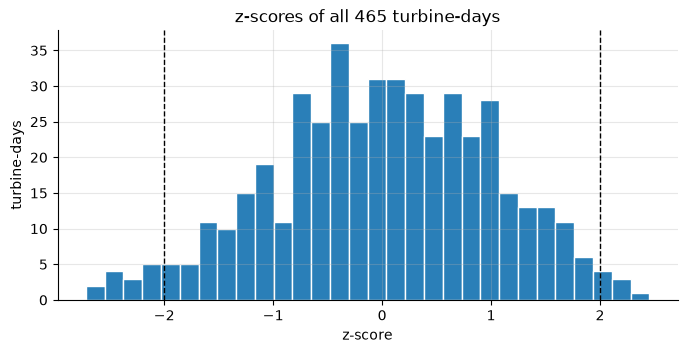

20 of 465 flagged (4.3%)


In [11]:
daily = (
    raw.assign(date=raw["timestamp"].dt.date)
    .groupby(["date", "turbine_id"])["power_output"]
    .mean()
    .rename("avg_power_mw")
    .reset_index()
)
by_day = daily.groupby("date")["avg_power_mw"]
daily["z_score"] = (daily["avg_power_mw"] - by_day.transform("mean")) / by_day.transform(
    "std", ddof=0
)

fig, ax = plt.subplots()
ax.hist(daily["z_score"], bins=30, color=COLOR, edgecolor="white")
for line in (-2, 2):
    ax.axvline(line, color="black", linestyle="--", linewidth=1)
ax.set(title="z-scores of all 465 turbine-days", xlabel="z-score", ylabel="turbine-days")
plt.show()

flagged = daily[daily["z_score"].abs() > 2]
print(f"{len(flagged)} of {len(daily)} flagged ({len(flagged) / len(daily):.1%})")

About 4.5% of normally distributed values fall outside 2 SD by chance, so 4.3% suggests most flags are ordinary variation.

Cross-check against the pipeline output (run `uv run wind-farm` first):

In [12]:
pipeline = pd.read_csv(ROOT / "output" / "anomalies.csv")
ours = set(zip(flagged["date"].astype(str), flagged["turbine_id"]))
theirs = set(zip(pipeline["date"].astype(str), pipeline["turbine_id"]))
print("matches pipeline:", ours == theirs)

matches pipeline: True
